In [1]:
import os
import json
from dotenv import load_dotenv
from openai import OpenAI

import base64
from io import BytesIO
from PIL import Image

from pydantic import BaseModel, Field
from system_prompts import PACKAGE_MANAGER_SYSTEM_PROMPT_V5 as PACKAGE_MANAGER_SYSTEM_PROMPT

In [2]:
load_dotenv(override=True)

client = OpenAI(api_key=os.getenv("OPENAI_API_KEY"))

# OLLAMA_BASE_URL = "http://localhost:11434/v1"

# client = OpenAI(base_url=OLLAMA_BASE_URL, api_key='ollama')


In [3]:
from schemas import FlatResponse, Response, unflatten


In [4]:
item1 = {
    "refId": 0,
    "color": "green",
    "name": "Dispenser",
    "weight": 4,
    "dimensions": {
        "x": 9.5,
        "y": 3.25,
        "z": 4.5
    },
    "quantity": 1
}

item2 = {
    "refId": 1,
    "color": "blue",
    "name": "Tape",
    "weight": 0.3,
    "dimensions": {
        "x": 4.75,
        "y": 4.75,
        "z": 1
    },
    "quantity": 20
}

item3 = {
    "refId": 2,
    "color": "red",
    "name": "Stand",
    "weight": 17,
    "dimensions": {
        "x": 28,
        "y": 4.38,
        "z": 23.38
    },
    "quantity": 3
}

items = [item1, item2, item3]

box1 = {
    "weightMax": 65,
    "refId": 0,
    "name": "Small",
    "dimensions": {
        "x": 12,
        "y": 6,
        "z": 6.75
    }
}

box2 = {
    "weightMax": 80,
    "refId": 1,
    "name": "Medium",
    "dimensions": {
        "x": 14.5,
        "y": 6.75,
        "z": 12.75
    }
}
box3 = {
    "weightMax": 70,
    "refId": 2,
    "name": "Wide Low",
    "dimensions": {
        "x": 12,
        "y": 12,
        "z": 4.25
    } 
}
boxes = [box1, box2, box3]

In [5]:
from prompt_builder import build_system_prompt, build_user_prompt

USER_PROMPT = build_user_prompt(items, boxes)
print(USER_PROMPT)

items (3 rows)
refId|color|name|weight|x|y|z|quantity
0|green|Dispenser|4|9.5|3.25|4.5|1
1|blue|Tape|0.3|4.75|4.75|1|20
2|red|Stand|17|28|4.38|23.38|3

boxes (3 rows)
weightMax|refId|name|x|y|z
65|0|Small|12|6|6.75
80|1|Medium|14.5|6.75|12.75
70|2|Wide Low|12|12|4.25

item_stats (3 rows)
ref_id|name|qty|unit_volume|total_volume|total_weight|fits_a_box
0|Dispenser|1|138.938|138.938|4|true
1|Tape|20|22.562|451.25|6|true
2|Stand|3|2867.32|8601.97|51|false

box_stats (3 rows)
ref_id|name|volume|weightMax
0|Small|486|65
1|Medium|1247.91|80
2|Wide Low|612|70

fits (6 rows)
item|box|max_by_weight|rotations
0|0|16|9.5×4.5×3.25=2/layer×1, 9.5×3.25×4.5=1/layer×1
0|1|20|4.5×3.25×9.5=2/layer×3, 3.25×4.5×9.5=1/layer×4, 9.5×3.25×4.5=4/layer×1, 9.5×4.5×3.25=3/layer×1
0|2|17|4.5×9.5×3.25=1/layer×2, 9.5×4.5×3.25=2/layer×1
1|0|216|1×4.75×4.75=1/layer×12, 4.75×4.75×1=6/layer×2, 4.75×1×4.75=6/layer×2
1|1|266|4.75×4.75×1=12/layer×3, 4.75×1×4.75=12/layer×3, 1×4.75×4.75=2/layer×14
1|2|233|4.75×4.75×1=8/layer

In [6]:
messages = [
    {"role": "system", "content": build_system_prompt(items)},
    {"role": "user", "content": USER_PROMPT}
]
print(messages)

[{'role': 'system', 'content': "You are a 3D packing planner. Return a packing plan as JSON matching the schema. It drives a packing diagram, so all values must be exact.\n\nPriorities, in order:\n1. Pack every unit. If impossible, maximize units packed.\n2. Fewest boxes.\n3. Least total internal box volume.\n4. Lowest fill height per box: boxes may be cut down, so keep all free space on top.\n5. Balanced, stable load that is simple to pack.\n\nCoordinates: origin at the box's inside back-left-bottom corner. X = height (up), Y = depth (back to front), Z = span (left to right). Dimensions are X × Y × Z. With pos [x, y, z] and dims [dx, dy, dz], a unit occupies [x, x+dx] × [y, y+dy] × [z, z+dz].\n\nInput tables have a header row, then one row per record. x|y|z are dimensions; box dimensions are INTERNAL; weightMax is the box's contents weight limit.\n\nPrecomputed facts (exact; use them, do not recompute):\n- fits: for each item × box pair that fits, max_by_weight is how many units the b

In [7]:
response = client.chat.completions.parse(
    model="gpt-5.4-mini",
    reasoning_effort="medium",
    messages=messages,
    response_format=FlatResponse
)
print(response.usage.completion_tokens_details.reasoning_tokens)
flat = response.choices[0].message.parsed
plan = unflatten(flat, items, boxes)
plan

14747


Response(length_unit=None, weight_unit=None, coordinate_system=CoordinateSystem(origin='inside_back_left_bottom', x_direction='bottom_to_top', y_direction='back_to_front', z_direction='left_to_right', position_reference='minimum_coordinate_corner'), boxes=[Boxes(dimensions=Dimensions(x=14.5, y=6.75, z=12.75), ref_id=1, name='Medium', max_contents_weight=80.0, items=[PackedItem(ref_id=1, color='blue', name='Tape', weight=0.3, dimensions=Dimensions(x=1.0, y=1.0, z=4.75), quantity=1, packed_index=1, placement_position=PlacementPosition(x=0.0, y=0.875, z=1.625)), PackedItem(ref_id=1, color='blue', name='Tape', weight=0.3, dimensions=Dimensions(x=1.0, y=1.0, z=4.75), quantity=1, packed_index=2, placement_position=PlacementPosition(x=0.0, y=0.875, z=6.375)), PackedItem(ref_id=1, color='blue', name='Tape', weight=0.3, dimensions=Dimensions(x=1.0, y=1.0, z=4.75), quantity=1, packed_index=3, placement_position=PlacementPosition(x=0.0, y=1.875, z=1.625)), PackedItem(ref_id=1, color='blue', name=

In [8]:
# Plan is validated in code; errors go back until a plan passes
from planner import plan_with_validation

tool_messages = [
    {"role": "system", "content": build_system_prompt(items, with_validator=True)},
    {"role": "user", "content": USER_PROMPT},
]
result = plan_with_validation(
    client, "gpt-5.4-mini", tool_messages, items, boxes,
    reasoning_effort="low",
)
print(f"ok={result.ok} rounds={result.rounds} improved={result.improved} reasoning_tokens={result.reasoning_tokens}")
print("errors:", result.errors)
print("hints:", result.hints)
flat = result.flat
plan = unflatten(flat, items, boxes)
plan

ok=True rounds=2 improved=False reasoning_tokens=3699
errors: []
hints: ['box 1: a Tape (4.75×1×4.75) fits on the free floor at y=4.75, z=0, but units are stacked up to x=10; fill the floor before stacking']


Response(length_unit=None, weight_unit=None, coordinate_system=CoordinateSystem(origin='inside_back_left_bottom', x_direction='bottom_to_top', y_direction='back_to_front', z_direction='left_to_right', position_reference='minimum_coordinate_corner'), boxes=[Boxes(dimensions=Dimensions(x=14.5, y=6.75, z=12.75), ref_id=1, name='Medium', max_contents_weight=80.0, items=[PackedItem(ref_id=0, color='green', name='Dispenser', weight=4.0, dimensions=Dimensions(x=9.5, y=4.5, z=3.25), quantity=1, packed_index=1, placement_position=PlacementPosition(x=0.0, y=0.0, z=0.0)), PackedItem(ref_id=1, color='blue', name='Tape', weight=0.3, dimensions=Dimensions(x=1.0, y=4.75, z=4.75), quantity=1, packed_index=2, placement_position=PlacementPosition(x=0.0, y=0.0, z=3.25)), PackedItem(ref_id=1, color='blue', name='Tape', weight=0.3, dimensions=Dimensions(x=1.0, y=4.75, z=4.75), quantity=1, packed_index=3, placement_position=PlacementPosition(x=0.0, y=0.0, z=8.0)), PackedItem(ref_id=1, color='blue', name='Ta

In [7]:
# OLLAMA
response = client.chat.completions.parse(
    model="llama3.2",
    messages=messages,
    response_format=FlatResponse
)
flat = response.choices[0].message.parsed
plan = unflatten(flat, items, boxes)
plan

Response(length_unit='in', weight_unit='lb', coordinate_system=CoordinateSystem(origin='inside_back_left_bottom', x_direction='bottom_to_top', y_direction='back_to_front', z_direction='left_to_right', position_reference='minimum_coordinate_corner'), boxes=[Boxes(dimensions=Dimensions(x=12.0, y=6.0, z=6.75), ref_id=0, name='Small', max_contents_weight=65.0, items=[PackedItem(ref_id=0, color='green', name='Dispenser', weight=4.0, dimensions=Dimensions(x=9.0, y=4.0, z=4.0), quantity=1, packed_index=1, placement_position=PlacementPosition(x=0.0, y=0.0, z=0.0))]), Boxes(dimensions=Dimensions(x=14.5, y=6.75, z=12.75), ref_id=1, name='Medium', max_contents_weight=80.0, items=[PackedItem(ref_id=1, color='blue', name='Tape', weight=0.3, dimensions=Dimensions(x=4.0, y=4.75, z=4.75), quantity=1, packed_index=2, placement_position=PlacementPosition(x=9.5, y=0.0, z=0.0))]), Boxes(dimensions=Dimensions(x=12.0, y=12.0, z=4.25), ref_id=2, name='Wide Low', max_contents_weight=70.0, items=[PackedItem(re

In [8]:
flat

FlatResponse(length_unit='in', weight_unit='lb', boxes=[BoxRow(box=1, ref_id=0), BoxRow(box=2, ref_id=1), BoxRow(box=3, ref_id=2)], placements=[PlacementRow(box=1, seq=1, ref_id=0, pos=[0.0, 0.0, 0.0], dims=[9.0, 4.0, 4.0]), PlacementRow(box=2, seq=2, ref_id=1, pos=[9.5, 0.0, 0.0], dims=[4.0, 4.75, 4.75]), PlacementRow(box=3, seq=3, ref_id=2, pos=[12.0, 8.75, 0.0], dims=[16.0, 20.0, 23.38])], leftovers=[LeftoverRow(ref_id=1, quantity=19, reason='Insufficient box'), LeftoverRow(ref_id=2, quantity=17, reason='Insufficient box')])

In [9]:
flat.model_dump()

{'length_unit': None,
 'weight_unit': None,
 'boxes': [{'box': 1, 'ref_id': 1}],
 'placements': [{'box': 1,
   'seq': 1,
   'ref_id': 0,
   'pos': [0.0, 0.0, 0.0],
   'dims': [4.5, 3.25, 9.5]},
  {'box': 1,
   'seq': 2,
   'ref_id': 1,
   'pos': [0.0, 3.25, 0.0],
   'dims': [4.75, 1.0, 4.75]},
  {'box': 1,
   'seq': 3,
   'ref_id': 1,
   'pos': [0.0, 3.25, 4.75],
   'dims': [4.75, 1.0, 4.75]},
  {'box': 1,
   'seq': 4,
   'ref_id': 1,
   'pos': [0.0, 4.25, 0.0],
   'dims': [4.75, 1.0, 4.75]},
  {'box': 1,
   'seq': 5,
   'ref_id': 1,
   'pos': [0.0, 4.25, 4.75],
   'dims': [4.75, 1.0, 4.75]},
  {'box': 1,
   'seq': 6,
   'ref_id': 1,
   'pos': [0.0, 5.25, 0.0],
   'dims': [4.75, 1.0, 4.75]},
  {'box': 1,
   'seq': 7,
   'ref_id': 1,
   'pos': [0.0, 5.25, 4.75],
   'dims': [4.75, 1.0, 4.75]},
  {'box': 1,
   'seq': 8,
   'ref_id': 1,
   'pos': [4.5, 0.0, 0.0],
   'dims': [4.75, 1.0, 4.75]},
  {'box': 1,
   'seq': 9,
   'ref_id': 1,
   'pos': [4.5, 0.0, 4.75],
   'dims': [4.75, 1.0, 4.75

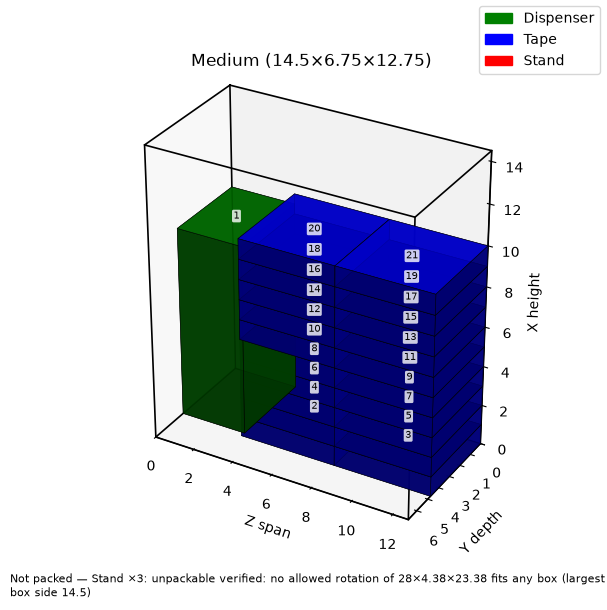

In [10]:
from visualize import render_plan

plan = unflatten(flat, items, boxes)
fig = render_plan(plan, path="plan.svg")

In [11]:
# Plotly: interactive (rotate/zoom/hover); WebGL depth buffer
from render_plotly import render_plotly

render_plotly(plan)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'hoverinfo': 'skip',
              'line': {'color': 'black', 'width': 4},
              'mode': 'lines',
              'scene': 'scene',
              'showlegend': False,
              'type': 'scatter3d',
              'x': [0, 12.75, None, 12.75, 12.75, None, 12.75, 0, None, 0, 0,
                    None, 0, 12.75, None, 12.75, 12.75, None, 12.75, 0, None, 0, 0,
                    None, 0, 0, None, 12.75, 12.75, None, 12.75, 12.75, None, 0, 0,
                    None],
              'y': [0, 0, None, 0, 6.75, None, 6.75, 6.75, None, 6.75, 0, None, 0,
                    0, None, 0, 6.75, None, 6.75, 6.75, None, 6.75, 0, None, 0, 0,
                    None, 0, 0, None, 6.75, 6.75, None, 6.75, 6.75, None],
              'z': [0, 0, None, 0, 0, None, 0, 0, None, 0, 0, None, 14.5, 14.5,
                    None, 14.5, 14.5, None, 14.5, 14.5, None, 14.5, 14.5, None, 0,
                    14.5, None, 0, 14.5, None, 0, 14.5, None, 0, 14.5, None]},
             {'color': '#008000',
              'flatshading': True,
              'hovertemplate': ('<b>Dispenser</b> · step 1<br>p' ... 'ze 9.5×4.5×3.25<extra></extra>'),
              'i': [0, 0, 4, 4, 0, 0, 3, 3, 0, 0, 1, 1],
              'j': [1, 2, 5, 6, 1, 5, 2, 6, 3, 7, 2, 6],
              'k': [2, 3, 6, 7, 5, 4, 6, 7, 7, 4, 6, 5],
              'legendgroup': 'Dispenser',
              'lighting': {'ambient': 0.6, 'diffuse': 0.6, 'specular': 0.1},
              'name': 'Dispenser',
              'opacity': 1.0,
              'scene': 'scene',
              'showlegend': True,
              'type': 'mesh3d',
              'x': [0.03, 3.22, 3.22, 0.03, 0.03, 3.22, 3.22, 0.03],
              'y': [0.03, 0.03, 4.47, 4.47, 0.03, 0.03, 4.47, 4.47],
              'z': [0.03, 0.03, 0.03, 0.03, 9.47, 9.47, 9.47, 9.47]},
             {'color': '#0000ff',
              'flatshading': True,
              'hovertemplate': '<b>Tape</b> · step 2<br>pos x=0, y=0, z=3.25<br>size 1×4.75×4.75<extra></extra>',
              'i': [0, 0, 4, 4, 0, 0, 3, 3, 0, 0, 1, 1],
              'j': [1, 2, 5, 6, 1, 5, 2, 6, 3, 7, 2, 6],
              'k': [2, 3, 6, 7, 5, 4, 6, 7, 7, 4, 6, 5],
              'legendgroup': 'Tape',
              'lighting': {'ambient': 0.6, 'diffuse': 0.6, 'specular': 0.1},
              'name': 'Tape',
              'opacity': 1.0,
              'scene': 'scene',
              'showlegend': True,
              'type': 'mesh3d',
              'x': [3.28, 7.97, 7.97, 3.28, 3.28, 7.97, 7.97, 3.28],
              'y': [0.03, 0.03, 4.72, 4.72, 0.03, 0.03, 4.72, 4.72],
              'z': [0.03, 0.03, 0.03, 0.03, 0.97, 0.97, 0.97, 0.97]},
             {'color': '#0000ff',
              'flatshading': True,
              'hovertemplate': '<b>Tape</b> · step 3<br>pos x=0, y=0, z=8<br>size 1×4.75×4.75<extra></extra>',
              'i': [0, 0, 4, 4, 0, 0, 3, 3, 0, 0, 1, 1],
              'j': [1, 2, 5, 6, 1, 5, 2, 6, 3, 7, 2, 6],
              'k': [2, 3, 6, 7, 5, 4, 6, 7, 7, 4, 6, 5],
              'legendgroup': 'Tape',
              'lighting': {'ambient': 0.6, 'diffuse': 0.6, 'specular': 0.1},
              'name': 'Tape',
              'opacity': 1.0,
              'scene': 'scene',
              'showlegend': False,
              'type': 'mesh3d',
              'x': [8.03, 12.72, 12.72, 8.03, 8.03, 12.72, 12.72, 8.03],
              'y': [0.03, 0.03, 4.72, 4.72, 0.03, 0.03, 4.72, 4.72],
              'z': [0.03, 0.03, 0.03, 0.03, 0.97, 0.97, 0.97, 0.97]},
             {'color': '#0000ff',
              'flatshading': True,
              'hovertemplate': '<b>Tape</b> · step 4<br>pos x=1, y=0, z=3.25<br>size 1×4.75×4.75<extra></extra>',
              'i': [0, 0, 4, 4, 0, 0, 3, 3, 0, 0, 1, 1],
              'j': [1, 2, 5, 6, 1, 5, 2, 6, 3, 7, 2, 6],
              'k': [2, 3, 6, 7, 5, 4, 6, 7, 7, 4, 6, 5],
              'legendgroup': 'Tape',
              'lighting': {'ambient': 0.6, 'diffuse': 0.6, 'specular': 0.1},
              'name': 'Tape',
           

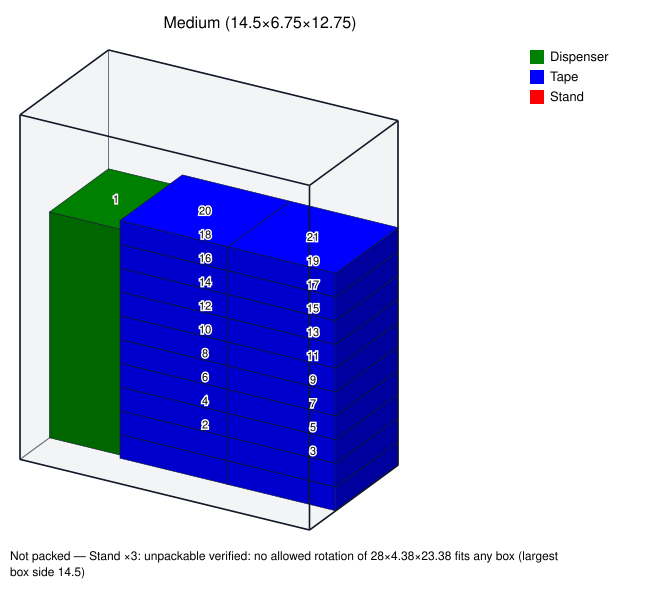

In [12]:
# Isometric SVG: no extra dependencies, small file, real text labels
from IPython.display import SVG
from render_svg import render_svg

svg = render_svg(plan)
SVG(svg)

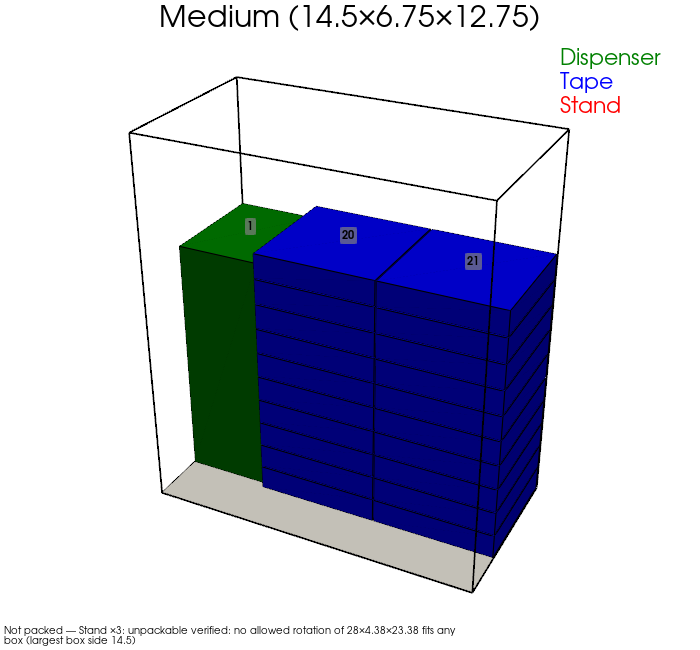

In [13]:
# PyVista (VTK): lit off-screen render -> PIL image
from render_pyvista import render_pyvista

render_pyvista(plan)

In [14]:
# vedo (VTK): same idea as PyVista with vedo's API -> PIL image
from render_vedo import render_vedo

render_vedo(plan)

AttributeError: 'NoneType' object has no attribute '__array_interface__'

In [15]:
# three.js: self-contained HTML page with orbit controls and a step slider
from IPython.display import HTML
from render_threejs import render_threejs, threejs_iframe

page = render_threejs(plan)
HTML(threejs_iframe(page))

/Users/jomarimacaraig/Desktop/projects/package-manager/.venv/lib/python3.12/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")
